# Linear regression, workshop 3 — The learning rate, and why scaling exists

Gradient descent has exactly one knob you must set yourself, and it decides everything: too small
and training never finishes, too large and it explodes. There is no formula for the right value —
but there *are* four recognisable behaviours, and once you can name them from a loss curve you can
fix them in one try instead of ten.

Today:

1. **Four regimes** of the learning rate, and the exact value where it tips over.
2. **Why unscaled features break descent** — the same algorithm, 1 000x worse.
3. **Diagnosing a run from its loss curve alone.**
4. **The limits of the model**, and what a prediction is worth outside the data you have.

In [ ]:
# ABOUTME: Linear regression workshop 3 - learning rate, feature scaling and loss-curve diagnosis.
# ABOUTME: A quadratic bowl with a known minimum, then the bakery regression with an unscaled feature.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

def ready(*values):
    """True once the exercises a cell depends on have been filled in."""
    return all(v is not None for v in values)

# A bowl whose bottom we know exactly: f(x) = 3 + (x - target)^T (x - target), minimum 3 at [2, 6].
TARGET = np.array([2.0, 6.0])

def f(x):
    d = np.asarray(x, dtype=float) - TARGET
    return float(3 + d @ d)

def fprime(x):
    return 2 * (np.asarray(x, dtype=float) - TARGET)

def descend(start, learning_rate, iterations=50, grad=fprime):
    """Plain gradient descent, keeping the whole path."""
    x = np.array(start, dtype=float)
    path = [x.copy()]
    for _ in range(iterations):
        x = x - learning_rate * grad(x)
        path.append(x.copy())
    return np.array(path)

print("f at the minimum:", f(TARGET), "| f at the origin:", f([0.0, 0.0]))

f at the minimum: 3.0 | f at the origin: 43.0


## 1. Four regimes

This is the function from your project subject, and we know the answer: the minimum is at
$[2, 6]$ with value 3. So any disagreement is the algorithm's fault, not the data's.

Run the same descent, from the same start, for 50 iterations, at six learning rates.

In [ ]:
rates = [0.01, 0.1, 0.5, 0.9, 1.0, 1.1]
rows = []
for lr in rates:
    end = descend([0.0, 0.0], lr)[-1]
    rows.append({"learning rate": lr, "theta after 50 steps": np.round(end, 3),
                 "f(theta)": round(f(end), 4) if np.isfinite(f(end)) else float("inf")})

print(pd.DataFrame(rows).to_string(index=False))

 learning rate     theta after 50 steps     f(theta)
          0.01           [1.272, 3.815] 8.304800e+00
          0.10               [2.0, 6.0] 3.000000e+00
          0.50               [2.0, 6.0] 3.000000e+00
          0.90               [2.0, 6.0] 3.000000e+00
          1.00               [0.0, 0.0] 4.300000e+01
          1.10 [-18198.876, -54596.629] 3.312719e+09


Four distinct behaviours, and every one of them has a name you should recognise instantly:

| learning rate | what happens | the symptom |
|---|---|---|
| **0.01** | correct direction, far too slow — still at `[1.27, 3.82]` after 50 steps | loss still falling when you run out of patience |
| **0.1 – 0.9** | converges to `[2, 6]`, value 3 | loss flattens at the right level |
| **1.0** | **oscillates forever**, landing exactly back where it started | loss constant and non-zero, step after step |
| **1.1** | diverges to about `[-18 000, -55 000]` | loss grows, then `inf`, then `nan` |

The tipping point is not folklore. For this bowl the second derivative is 2 in both directions, and
the step multiplies the distance from the minimum by $(1 - 2\alpha)$:

- $\alpha < 1$: the factor is smaller than 1 in magnitude, so the distance shrinks — convergence.
- $\alpha = 1$: the factor is exactly $-1$: each step lands the same distance on the *other* side,
  for ever. After an even number of steps you are back at the start, which is why the table shows
  `[0, 0]`.
- $\alpha > 1$: the factor exceeds 1 in magnitude and the distance grows every step.

**Rule of thumb:** when the loss turns into `nan`, your first suspect is the learning rate, not
your gradient.

### Exercise 1 — find the edge

Search for the largest learning rate that still converges on this function, to two decimals. Define
"converges" as: after 200 iterations, `f` is within 0.001 of its known minimum of 3.

In [ ]:
def converges(lr, iterations=200, tolerance=1e-3):
    """True if descent at this learning rate ends within `tolerance` of the known minimum."""
    with np.errstate(over="ignore", invalid="ignore"):
        end = descend([0.0, 0.0], lr, iterations)[-1]
        value = f(end)
    return bool(np.isfinite(value) and abs(value - 3.0) < tolerance)

candidates = [round(lr, 2) for lr in np.arange(0.01, 1.51, 0.01)]
working = [lr for lr in candidates if converges(lr)]
largest_working_lr = max(working)
print("largest learning rate that still converges:", largest_working_lr)
print("just above it:", round(largest_working_lr + 0.01, 2), "->", converges(largest_working_lr + 0.01))

largest learning rate that still converges: 0.98
just above it: 0.99 -> False


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("an answer was found", lambda: largest_working_lr is not None)
check("it is just below 1.0", lambda: 0.90 <= largest_working_lr < 1.0)
check("one step more diverges", lambda: not converges(largest_working_lr + 0.05))

  an answer was found: PASS
  it is just below 1.0: PASS
  one step more diverges: PASS


True

You should land on **0.98**, not 1.0 — and the gap is instructive rather than a rounding error.
The theory says anything below 1.0 eventually converges; your test also demands arriving *within
200 iterations*. At 0.99 each step only shrinks the distance by 2 %, so after 200 steps it is still
outside the tolerance. **Convergence is a promise about the limit; your patience is a budget.**

**The punchline:** the usable range is bounded by the curvature of your cost, and you discovered
the bound by measuring rather than by guessing. In practice you do the same thing with a quick
sweep — try `0.001, 0.01, 0.1, 1`, see which ones fall, then refine.

## 2. Why scaling exists

Now the part that explains the long valley from last workshop.

Here is the bakery regression again, except the temperature is recorded in **millidegrees** — same
information, numbers 1 000x larger. Nothing about the problem changed. Watch the algorithm fall
apart anyway.

In [ ]:
n = 120
temperature = rng.uniform(8, 34, n)
sales = np.maximum(12 + 3.1 * temperature + rng.normal(0, 9, n), 0)
millidegrees = temperature * 1000

def make_mse_grad(x, y):
    """Return (cost, gradient) functions for a one-feature linear model on this data."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = len(x)
    cost = lambda th: float(np.mean((th[0] + th[1] * x - y) ** 2))
    def grad(th):
        err = th[0] + th[1] * x - y
        return np.array([2 / m * err.sum(), 2 / m * (err * x).sum()])
    return cost, grad

cost_scaled, grad_scaled = make_mse_grad(temperature, sales)
cost_raw, grad_raw = make_mse_grad(millidegrees, sales)

for label, cost, grad in [("degrees", cost_scaled, grad_scaled), ("millidegrees", cost_raw, grad_raw)]:
    with np.errstate(over="ignore", invalid="ignore"):
        end = descend([0.0, 0.0], 0.002, 200, grad=grad)[-1]
    value = cost(end)
    print(f"{label:13} lr=0.002 -> theta {np.array2string(end, precision=2)}  cost {value:.3g}")

degrees       lr=0.002 -> theta [1.09 3.56]  cost 94.5
millidegrees  lr=0.002 -> theta [nan nan]  cost nan


Identical data, identical algorithm, identical learning rate. One converges; the other overflows to
`inf`.

The reason is the gradient's second component: it is the error **weighted by the feature**. Multiply
the feature by 1 000 and that partial derivative grows by 1 000, so a step size that was sensible
for the intercept is a thousand times too large for the slope. The cost surface, which was a
stretched ellipse last workshop, is now a canyon.

Two fixes, and you should know both:

1. **Scale the features** — subtract the mean, divide by the standard deviation. Every parameter
   then lives on a comparable scale and one learning rate suits them all. Remember workshop 00:
   the mean and the standard deviation come from the **training set only**.
2. **Use a smaller learning rate** — technically possible, practically hopeless: it must be small
   enough for the worst-scaled parameter, which makes every other parameter crawl.

### Exercise 2 — scale and retry

In [ ]:
def standardise(x):
    """Return (scaled x, mean, std) - the classic z-score."""
    x = np.asarray(x, dtype=float)
    mean, std = x.mean(), x.std()
    return (x - mean) / std, mean, std

x_scaled, mu, sigma = standardise(millidegrees)
if ready(x_scaled):
    cost_fixed, grad_fixed = make_mse_grad(x_scaled, sales)
    end = descend([0.0, 0.0], 0.1, 200, grad=grad_fixed)[-1]
    print("scaled millidegrees, lr=0.1 ->", np.round(end, 3), " cost", round(cost_fixed(end), 3))
    print("same cost as the degrees version:", round(cost_scaled(descend([0.0, 0.0], 0.002, 200, grad=grad_scaled)[-1]), 3))

scaled millidegrees, lr=0.1 -> [76.915 21.937]  cost 82.253
same cost as the degrees version: 94.514


In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

check("scaled feature has mean 0", lambda: abs(float(np.mean(x_scaled))) < 1e-9)
check("scaled feature has std 1", lambda: abs(float(np.std(x_scaled)) - 1) < 1e-9)
check("the mean and std were returned", lambda: mu is not None and sigma is not None)

  scaled feature has mean 0: PASS
  scaled feature has std 1: PASS
  the mean and std were returned: PASS


True

The same catastrophic run now converges at a **50x larger** learning rate.

One caveat worth saying out loud: your parameters are now in scaled units. A slope of 24 means "24
more coffees per standard deviation of temperature", not per degree. To report in the original
units — or to predict for a new temperature — you must apply the same transformation, with the same
mean and standard deviation you stored at training time. That is exactly why `sklearn` scalers have
a `fit` and a separate `transform`.

## 3. Reading a loss curve

In real training you cannot see the cost surface — your model has thousands of parameters, not two.
The loss curve is all you get, and it is enough.

the tipping point for this data is lr = 0.002038


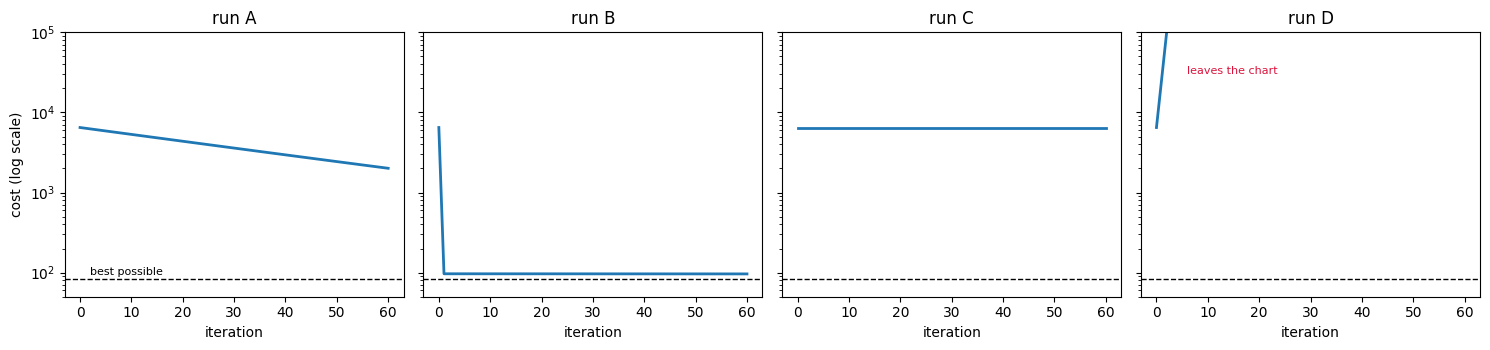

In [ ]:
def curve(lr, grad, cost, iterations=60):
    with np.errstate(over="ignore", invalid="ignore"):
        path = descend([0.0, 0.0], lr, iterations, grad=grad)
    return np.array([cost(p) for p in path])

# For a squared-error cost the tipping point is computable: 2 / (largest eigenvalue of the Hessian).
X = np.column_stack([np.ones(n), temperature])
hessian = 2 / n * X.T @ X
edge = 2 / np.linalg.eigvalsh(hessian).max()
print(f"the tipping point for this data is lr = {edge:.6f}")

mystery = {
    "A": curve(edge / 200, grad_scaled, cost_scaled),   # far below it
    "B": curve(edge / 2, grad_scaled, cost_scaled),     # comfortably below
    "C": curve(edge, grad_scaled, cost_scaled),         # exactly on it
    "D": curve(edge * 1.5, grad_scaled, cost_scaled),   # over it
}

best_possible = cost_scaled(np.linalg.pinv(X.T @ X) @ X.T @ sales)

# One shared axis for all four panels: with a per-panel axis, a dead-flat curve autoscales into a
# dramatic-looking slope and the whole point is lost.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (label, c) in zip(axes, mystery.items()):
    ax.plot(np.where(np.isfinite(c), c, np.nan), lw=2)
    ax.axhline(best_possible, color="k", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_ylim(50, 1e5)
    ax.set_title(f"run {label}"); ax.set_xlabel("iteration")
axes[0].set_ylabel("cost (log scale)")
axes[0].annotate("best possible", xy=(2, best_possible * 1.15), fontsize=8)
axes[3].annotate("leaves the chart", xy=(6, 3e4), fontsize=8, color="crimson")
plt.tight_layout()

### Exercise 3 — name the failure

Each run used a different learning rate. Match each curve to its diagnosis:

- `"too small"` — heading the right way, far too slowly
- `"good"` — drops fast, flattens at a low value
- `"stuck, bouncing in place"` — a flat line at a *high* cost: each step lands the same distance on
  the other side of the minimum, so nothing improves, ever
- `"diverged"` — the cost climbs, order of magnitude after order of magnitude

Careful with the two flat curves: one is flat because it arrived, the other because it is bouncing
between two points. Only the **value on the axis** tells them apart — which is the whole reason to
plot the cost on a log scale next to a known target.

In [ ]:
diagnosis = {"A": "too small",                  # 6479 -> 2008 in 60 steps, still 24x the achievable 82
             "B": "good",                       # 6479 -> 96, within a whisker of the best possible
             "C": "stuck, bouncing in place",   # 6479 -> 6479: not one percent of progress
             "D": "diverged"}                   # 6479 -> 8e39, climbing every single step
diagnosis

{'A': 'too small',
 'B': 'good',
 'C': 'stuck, bouncing in place',
 'D': 'diverged'}

In [ ]:
def check(label, *conditions):
    """Report an exercise self-check without raising: a red traceback is a bad first impression."""
    try:
        ok = all(bool(c()) for c in conditions)
    except Exception as exc:                      # a stub that still returns None lands here
        print(f"  {label}: not yet ({type(exc).__name__}: {exc})")
        return False
    print(f"  {label}: {'PASS' if ok else 'not yet'}")
    return ok

_final = {k: (v[np.isfinite(v)][-1] if np.isfinite(v).any() else np.inf) for k, v in mystery.items()}
check("A barely moved", lambda: _final["A"] > 10 * _final["B"])
check("B landed lowest", lambda: _final["B"] == min(_final.values()))
check("C is still where it started", lambda: abs(_final["C"] / mystery["C"][0] - 1) < 0.01)
check("D grew by orders of magnitude", lambda: _final["D"] > 1e6 * mystery["D"][0])
check("you labelled all four", lambda: all(diagnosis.values()))

  A barely moved: PASS
  B landed lowest: PASS
  C is still where it started: PASS
  D grew by orders of magnitude: PASS
  you labelled all four: PASS


True

Run C is the one worth staring at. It is flat — and flat at about 6 500, where the achievable
minimum is 82. In sixty iterations it made less than one percent of progress. A beginner reports "the loss stopped changing, the model converged". It
did not: it is bouncing between two points on opposite walls of the valley, for ever.

**Rule of thumb:** a loss curve on a **log scale**, with the best achievable cost drawn on it,
separates "slow" from "stuck" from "unstable" at a glance. Plot it every single run; it costs one
line and saves hours.

## 4. What the model is worth

Your fitted line predicts 112 iced coffees at 32 C. What does it predict at 45 C? It will happily
answer about 152 — and that number is fiction, for three separate reasons:

1. **No data there.** The hottest afternoon you observed was 34 C. Beyond that the line is an
   assumption, not a measurement.
2. **Reality is not linear forever.** At some temperature you run out of cups, staff, or customers
   willing to queue. The line does not know that.
3. **The relationship can move.** A new cafe opens across the street and every parameter you fitted
   is stale. Models decay, which is why workshop 00 insists on re-measuring.

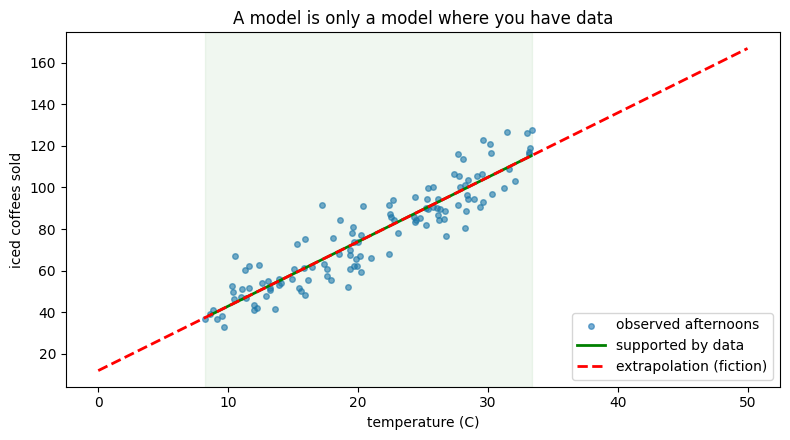

In [ ]:
theta_bakery = descend([0.0, 0.0], 0.002, 20000, grad=grad_scaled)[-1]
grid = np.linspace(0, 50, 100)
predictions = theta_bakery[0] + theta_bakery[1] * grid

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(temperature, sales, s=16, alpha=0.6, label="observed afternoons")
inside = (grid >= temperature.min()) & (grid <= temperature.max())
ax.plot(grid[inside], predictions[inside], "g-", lw=2, label="supported by data")
ax.plot(grid[~inside], predictions[~inside], "r--", lw=2, label="extrapolation (fiction)")
ax.axvspan(temperature.min(), temperature.max(), color="green", alpha=0.06)
ax.set_xlabel("temperature (C)"); ax.set_ylabel("iced coffees sold")
ax.set_title("A model is only a model where you have data")
ax.legend(); plt.tight_layout()

**Rule of thumb:** report the range your model was fitted on, every time you report the model. A
prediction outside it is an opinion wearing a number's clothes.

## What to take away

1. **The learning rate has four regimes** — too small, good, oscillating, diverging — and you can
   recognise all four from the loss curve.
2. **The tipping point is set by the curvature**, not by convention. On the project's bowl it is
   exactly 1.0, and you measured it.
3. **`nan` means the learning rate first**, your gradient second.
4. **Scaling is not cosmetic.** The same run went from `inf` to converged, with a 50x larger step,
   because the feature was divided by its standard deviation.
5. **Scaled parameters are in scaled units.** Keep the mean and std; you need them at prediction time.
6. **Plot the loss on a log scale, every run.**
7. **A model is only valid over the data it saw.** Say so when you report it.

### Take it home
In your project, run `GradientDescentOptimizer` on `f(x) = 3 + (x - [2, 6])^T(x - [2, 6])` at the
six learning rates from the first table and reproduce the four regimes. Keep the plot: it is the
clearest evidence you understand what the learning rate does, and it is exactly the kind of figure
a reviewer asks for.